# Assignment 1
## Exploring Real World Networks: Wikipedia "Squirrel" dataset
The following notebook includes all the code used for Assignment 1. It follows the following pipeline: dataset loading and cleaning, statistical analysis, comparison with benchmark models, and presenting of distribution statistics. Some of the tables, statistics, and graphs, alongside those produced in Gephi, were included in the report.

### Database selection
I selected the Wikipedia Article Networks, which represents page-to-page links for a specific topic. It is part of a bigger research project, MUSAE, which is presented in (\cite{rozemberczki2019multiscale}).  Nodes are represented as ID codes starting from 0, while edges correspond to the rows in the dataset, with $id1$ origin and $id2$ destination of the link between pages. The selected dataset from the repository is "Squirrel", with 5201 nodes and 198493 edges before cleaning.

### Necessary Imports

In [24]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import seaborn as sns


%matplotlib inline
#plot style
plt.style.use('default')
sns.set_palette("husl")

### Auxiliary Functions

In [25]:
#Function to load data from csv file, printing shape of dataset and removing missing rows
def load_data(filepath):
    """
    Load hyperlink data from a CSV file and remove rows with missing page IDs.

    Args:
        filepath (str): Path to the CSV file containing source and destination page IDs.

    Returns:
        pandas.DataFrame: Cleaned dataset containing the columns ``id1`` and ``id2``.
    """
    columns = [ 'id1','id2']
    
    # Load data
    df = pd.read_csv(filepath, names=columns, na_values=['\\N'])
    
    print(f"Loaded {len(df)} rows")
    print(f"Data shape: {df.shape}")
    
    # Remove rows with missing page IDs
    df_clean = df.dropna(subset=['id1', 'id2'])
    print(f"After removing missing connections: {len(df_clean)} links")
    
    return df_clean

In [26]:
#Function to create network/graph from the csv file, given the origin and destination columns in dataset
def create_network(df):
    """
    Create an undirected NetworkX graph from the hyperlink dataset.

    Args:
        df (pandas.DataFrame): Dataset containing source IDs in ``id1`` and
            destination IDs in ``id2``. Repeated links are stored as edge weights.

    Returns:
        networkx.Graph: Undirected graph with self-loops excluded.
    """
    
    # Create undirected graph (treating routes as bidirectional connections)
    G = nx.Graph()
    
    # Add edges for each link
    for _, row in df.iterrows():
        source = row['id1']
        dest = row['id2']
        
        # Skip self-loops
        if source != dest:
            if G.has_edge(source, dest):
                # Increment weight if edge already exists
                G[source][dest]['weight'] += 1
            else:
                # Add new edge with weight 1
                G.add_edge(source, dest, weight=1)
    
    print(f"Network created with {G.number_of_nodes()} pages and {G.number_of_edges()} link jumps")
    
    return G
    

In [27]:
#Function to compute the degree distribution of the network and plot it
def plot_degree_distribution(G):
    """
    Plot the network's degree distribution on linear and log-log scales,
    and print descriptive statistics of the degree sequence.

    Args:
        G (networkx.Graph): Network whose degree distribution is plotted.

    Returns:
        None
    """
    
    # Get degree sequence
    degrees = [G.degree(n) for n in G.nodes()]
    degree_counts = Counter(degrees)
    
    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Linear scale plot
    degrees_list = list(degree_counts.keys())
    counts_list = list(degree_counts.values())
    
    ax1.bar(degrees_list, counts_list, alpha=0.7, color='skyblue', edgecolor='black')
    ax1.set_xlabel('Degree')
    ax1.set_ylabel('Number of Pages visited')
    ax1.set_title('Degree Distribution (Linear Scale)')
    ax1.grid(True, alpha=0.3)
    
    # Log-log scale plot
    ax2.loglog(degrees_list, counts_list, 'bo', alpha=0.7, markersize=4)
    ax2.set_xlabel('Degree (log scale)')
    ax2.set_ylabel('Number of Pages visited (log scale)')
    ax2.set_title('Degree Distribution (Log-Log Scale)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('degree_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print basic statistics
    print(f"\nDegree Distribution Statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Max degree: {max(degrees)}")
    print(f"Min degree: {min(degrees)}")
    print(f"Standard deviation: {np.std(degrees):.2f}")

In [28]:
#Function to compute statistics of centrality in network
def calculate_centrality_measures(G):
    """
    Calculate degree, betweenness, closeness, and eigenvector centrality.

    Betweenness centrality is approximated by sampling up to 1,000 nodes
    for networks with more than 1,000 nodes. Closeness and eigenvector
    centrality are calculated on the largest connected component.

    Args:
        G (networkx.Graph): Network on which centrality measures are calculated.

    Returns:
        dict: Dictionary mapping each centrality measure to a dictionary
            of node IDs and their centrality scores.
    """
    centralities = {}
    
    # Degree centrality
    print("  - Degree centrality...")
    centralities['degree'] = nx.degree_centrality(G)
    
    # Betweenness centrality (using sampling for large networks)
    print("  - Betweenness centrality...")
    if G.number_of_nodes() > 1000:
        # Use sampling for large networks to speed up computation
        k = min(1000, G.number_of_nodes())
        centralities['betweenness'] = nx.betweenness_centrality(G, k=k, seed=42)
        print(f"    (using sampling with k={k} nodes)")
    else:
        centralities['betweenness'] = nx.betweenness_centrality(G)
    
    # Closeness centrality
    print("  - Closeness centrality...")
    # Only calculate for the largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G_largest = G.subgraph(largest_cc)
    closeness_largest = nx.closeness_centrality(G_largest)
    
    # Extend to full graph with 0 for disconnected nodes
    centralities['closeness'] = {node: closeness_largest.get(node, 0) for node in G.nodes()}
    
    # Eigenvector centrality
    print("  - Eigenvector centrality...")
    try:
        centralities['eigenvector'] = nx.eigenvector_centrality(G_largest, max_iter=1000)
        # Extend to full graph with 0 for disconnected nodes
        centralities['eigenvector'] = {node: centralities['eigenvector'].get(node, 0) for node in G.nodes()}
    except nx.PowerIterationFailedConvergence:
        print("    Warning: Eigenvector centrality failed to converge, using PageRank instead")
        centralities['eigenvector'] = nx.pagerank(G)
    
    return centralities

In [29]:
#Function to show the top pages for centrality measures
def display_top_pages(centralities, top_n=10):
    """
    Display the top N pages for each centrality measure.

    Args:
        centralities (dict): Dictionary of centrality measures, each containing
            node IDs and their centrality scores.
        top_n (int): Number of top pages to display for each measure.

    Returns:
        None
    """
    print(f"\n{'='*60}")
    print(f"TOP {top_n} PAGES BY CENTRALITY MEASURES")
    print(f"{'='*60}")
    
    for measure_name, measure_values in centralities.items():
        print(f"\n{measure_name.upper()} CENTRALITY:")
        print("-" * 40)
        
        # Sort pages by centrality value
        sorted_pages = sorted(measure_values.items(), key=lambda x: x[1], reverse=True)
        
        for i, (page, value) in enumerate(sorted_pages[:top_n], 1):
            print(f"{i:2d}. {str(page):>6} - {value:.6f}")

In [30]:
def network_summary(G, df):
    """
    Print descriptive statistics summarising the network's structure.

    Args:
        G (networkx.Graph): Network to summarise.
        df (pandas.DataFrame): Original cleaned hyperlink dataset, used to
            report the number of hyperlink records.

    Returns:
        None
    """

    # Extract largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G_lcc = G.subgraph(largest_cc).copy()

    N = G.number_of_nodes()
    M = G.number_of_edges()

    print("=" * 60)
    print("NETWORK SUMMARY")
    print("=" * 60)

    # Basic dimensions
    print(f"Number of articles (nodes): {N}")
    print(f"Number of unique edges: {M}")
    print(f"Hyperlink records in dataset: {len(df)}")

    # Connected components
    print(f"Connected components: {nx.number_connected_components(G)}")
    print(f"LCC size: {G_lcc.number_of_nodes()}")
    print(f"LCC proportion: {len(largest_cc)/N*100:.2f}%")

    # Basic network statistics
    print(f"Network density: {nx.density(G):.6f}")
    print(f"Average degree: {2*M/N:.4f}")

    # Clustering
    print(f"Average clustering: {nx.average_clustering(G):.4f}")
    print(f"Global transitivity: {nx.transitivity(G):.4f}")

    # Assortativity
    print(f"Degree assortativity: {nx.degree_assortativity_coefficient(G):.4f}")

    # Path-based measures (LCC)
    print(f"Average path length (LCC): {nx.average_shortest_path_length(G_lcc):.4f}")
    print(f"Network diameter (LCC): {nx.diameter(G_lcc)}")

### Loading of dataset

In [31]:
# File path
data_file = "datasets/squirrel_edges.csv"

# Load data
df = load_data(data_file)

# Display first few rows
print("\nFirst 5 rows of the data:")
print(df.head())

Loaded 217073 rows
Data shape: (217073, 2)
After removing missing connections: 217073 links

First 5 rows of the data:
    id1   id2
0  3475  2849
1  3475  3106
2  3475   808
3  3475  4555
4  3475  3563


### Creating network and statistical analysis

In [32]:
# Create network
G = create_network(df)

Network created with 5201 pages and 198353 link jumps


In [33]:
# Network summary
network_summary(G, df)

NETWORK SUMMARY
Number of articles (nodes): 5201
Number of unique edges: 198353
Hyperlink records in dataset: 217073
Connected components: 1
LCC size: 5201
LCC proportion: 100.00%
Network density: 0.014668
Average degree: 76.2749
Average clustering: 0.4222
Global transitivity: 0.3481
Degree assortativity: -0.2272
Average path length (LCC): 3.0906
Network diameter (LCC): 10


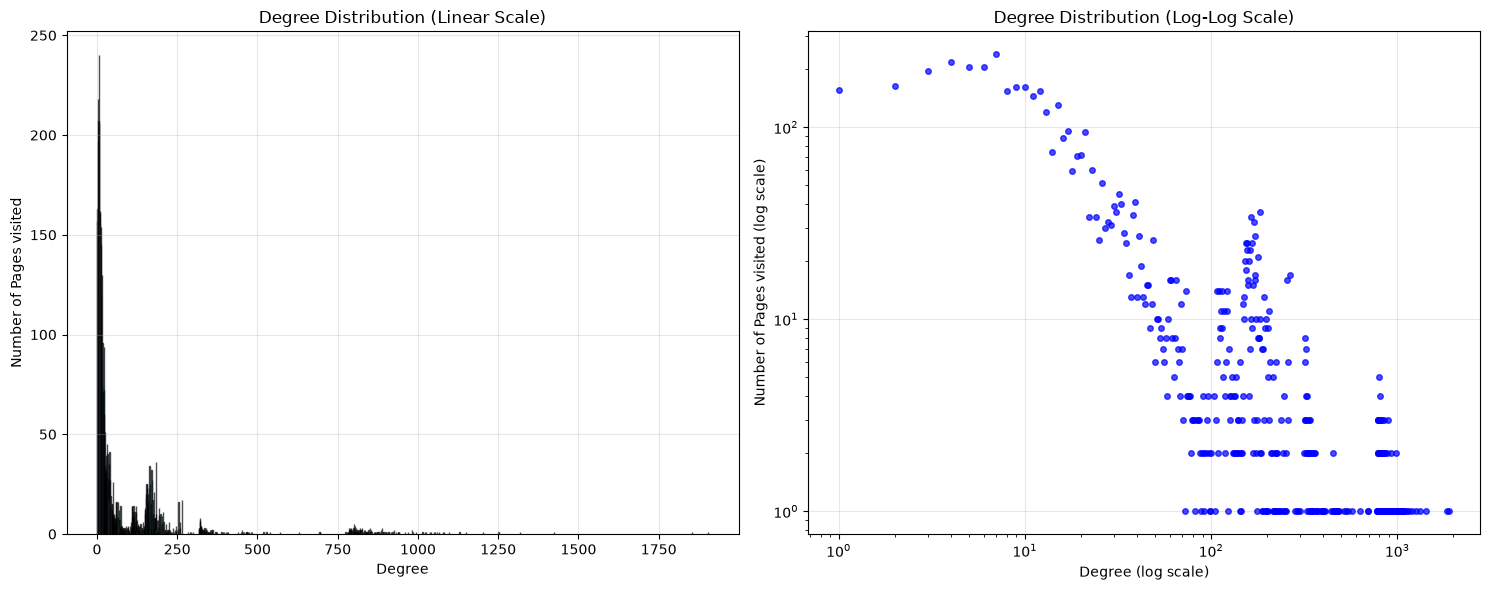


Degree Distribution Statistics:
Mean degree: 76.27
Median degree: 17.00
Max degree: 1903
Min degree: 1
Standard deviation: 161.44


In [34]:
# Plot degree distribution
plot_degree_distribution(G)

### Centrality Analysis

In [35]:
# Calculate centrality measures
centralities = calculate_centrality_measures(G)

  - Degree centrality...
  - Betweenness centrality...
    (using sampling with k=1000 nodes)
  - Closeness centrality...
  - Eigenvector centrality...


In [36]:
# Display top pages for centrality
display_top_pages(centralities, top_n=10)


TOP 10 PAGES BY CENTRALITY MEASURES

DEGREE CENTRALITY:
----------------------------------------
 1.   4346 - 0.365962
 2.   5112 - 0.356346
 3.   4365 - 0.273654
 4.   4903 - 0.253654
 5.   4303 - 0.240577
 6.   5095 - 0.231154
 7.   4419 - 0.220962
 8.   5033 - 0.217115
 9.   5063 - 0.210769
10.   4322 - 0.207885

BETWEENNESS CENTRALITY:
----------------------------------------
 1.   4346 - 0.130531
 2.   5112 - 0.093026
 3.   4303 - 0.040109
 4.   4903 - 0.039989
 5.   3290 - 0.026085
 6.   4841 - 0.026031
 7.   4989 - 0.025110
 8.   5194 - 0.025100
 9.   4365 - 0.023657
10.   5164 - 0.023407

CLOSENESS CENTRALITY:
----------------------------------------
 1.   4346 - 0.520260
 2.   5112 - 0.514546
 3.   4903 - 0.475363
 4.   4365 - 0.472641
 5.   4303 - 0.472084
 6.   5095 - 0.458069
 7.   4544 - 0.457706
 8.   5164 - 0.456982
 9.   4864 - 0.454864
10.   4419 - 0.454784

EIGENVECTOR CENTRALITY:
----------------------------------------
 1.   4346 - 0.070747
 2.   5112 - 0.070350
 3

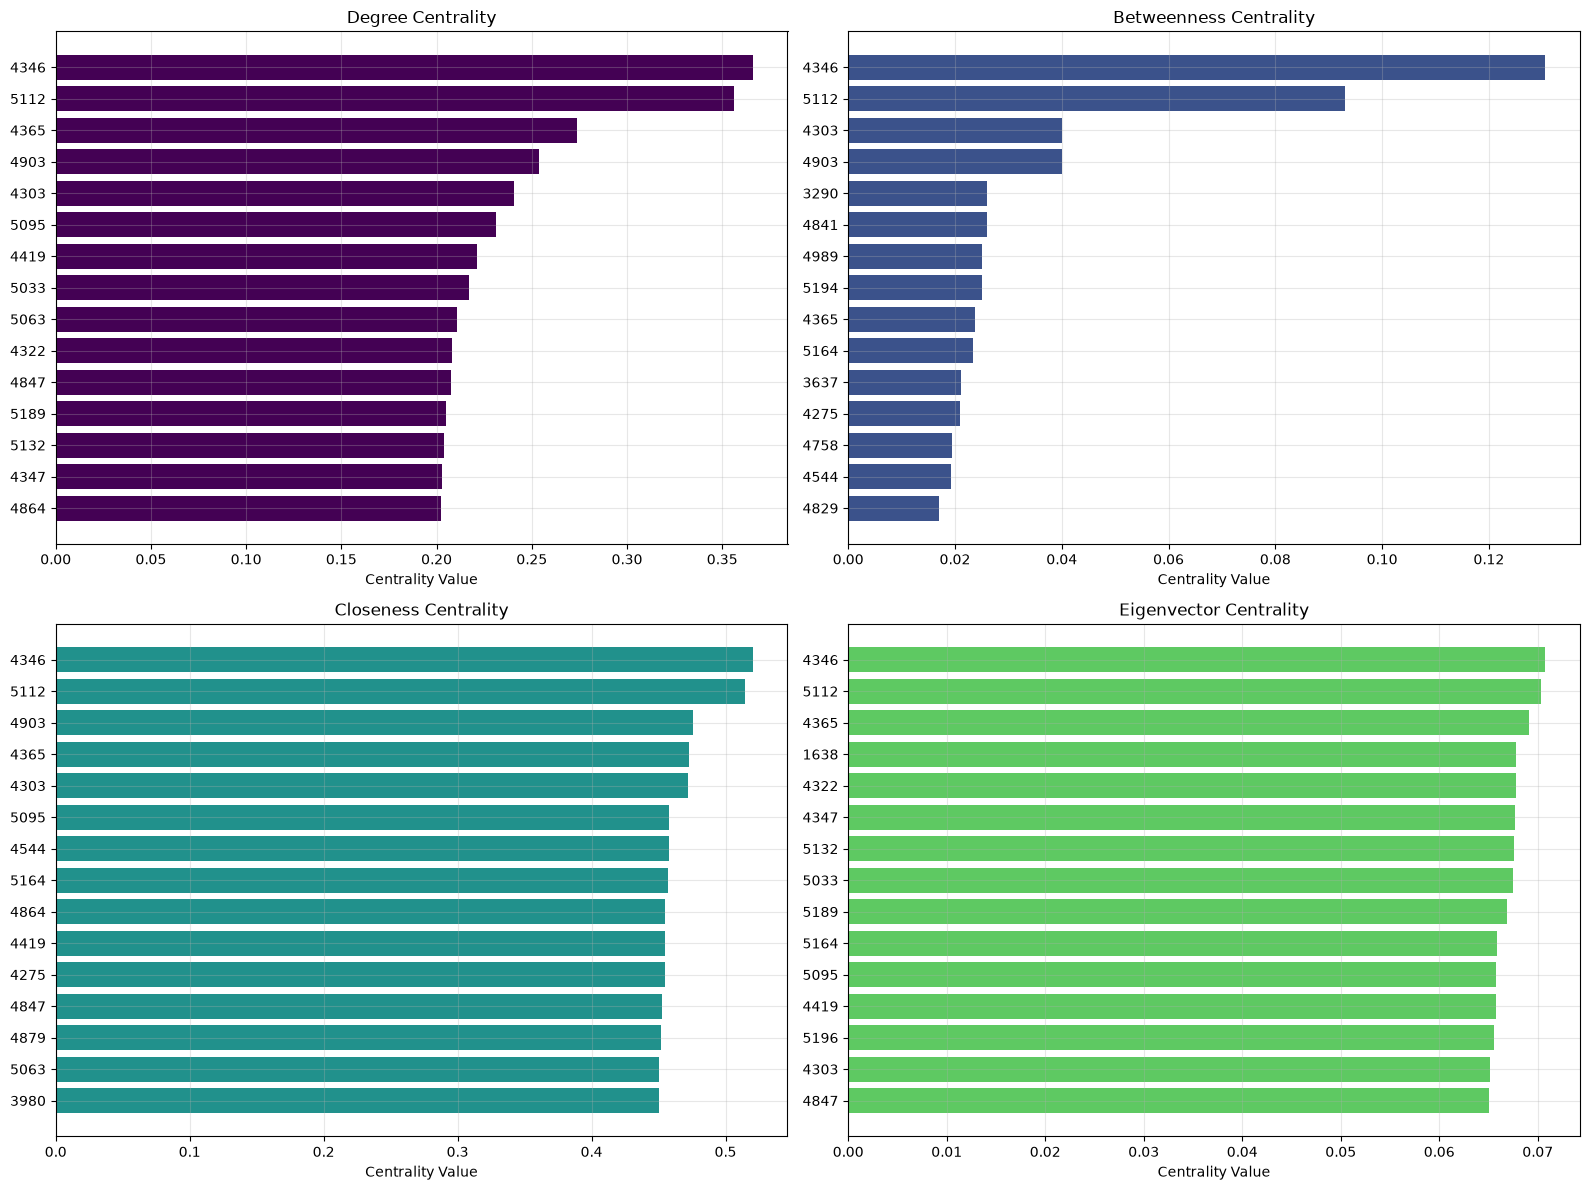

In [37]:
# Create a comparison plot of different centrality measures for top pages
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

centrality_names = ['degree', 'betweenness', 'closeness', 'eigenvector']
centrality_titles = ['Degree Centrality', 'Betweenness Centrality', 'Closeness Centrality', 'Eigenvector Centrality']

for i, (name, title) in enumerate(zip(centrality_names, centrality_titles)):
    # Get top 15 pages for this centrality measure
    sorted_pages = sorted(centralities[name].items(), key=lambda x: x[1], reverse=True)[:15]
    pages = [item[0] for item in sorted_pages]
    values = [item[1] for item in sorted_pages]
    
    # Create horizontal bar plot
    axes[i].barh(range(len(pages)), values, color=plt.cm.viridis(i/4))
    axes[i].set_yticks(range(len(pages)))
    axes[i].set_yticklabels(pages)
    axes[i].set_xlabel('Centrality Value')
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)
    
    # Invert y-axis to show highest values at top
    axes[i].invert_yaxis()

plt.tight_layout()
plt.savefig('centrality_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [38]:
# Extract the Largest Connected Component
largest_cc = max(nx.connected_components(G), key=len)
G_empirical = G.subgraph(largest_cc).copy()

# Basic network parameters
N = G_empirical.number_of_nodes()
M = G_empirical.number_of_edges()
avg_degree = 2 * M / N

print(f"Number of nodes: {N}")
print(f"Number of edges: {M}")
print(f"Average degree: {avg_degree:.3f}")

Number of nodes: 5201
Number of edges: 198353
Average degree: 76.275


### Comparison to canonical benchmark networks

In [39]:
# Generate canonical benchmark networks

# 1. Erdős–Rényi
G_ER = nx.gnm_random_graph(N, M, seed=42)

# 2. Watts–Strogatz
k_ws = max(2, round(avg_degree / 2) * 2)
k_ws = min(k_ws, N - 1 if (N - 1) % 2 == 0 else N - 2)

G_WS = nx.watts_strogatz_graph(
    N,
    k_ws,
    p=0.05,
    seed=42
)

# 3. Barabási–Albert
m_ba = max(1, round(avg_degree / 2))

G_BA = nx.barabasi_albert_graph(
    N,
    m_ba,
    seed=42
)

# Store all networks for comparison
networks = {
    "Empirical": G_empirical,
    "Erdos-Renyi": G_ER,
    "Watts-Strogatz": G_WS,
    "Barabasi-Albert": G_BA
}

print("Benchmark networks generated successfully.")

Benchmark networks generated successfully.


In [40]:
def calculate_network_metrics(G):
    """
    Calculate structural metrics for a network, using its largest connected
    component to calculate average shortest path length.

    Args:
        G (networkx.Graph): Network whose structural metrics are calculated.

    Returns:
        dict: Network metrics, including node and edge counts, average degree,
            average clustering, average path length, and degree assortativity.
    """

    # Extract largest connected component for path length
    largest_cc = max(nx.connected_components(G), key=len)
    G_lcc = G.subgraph(largest_cc)

    metrics = {
        "N": G.number_of_nodes(),
        "M": G.number_of_edges(),
        "Average Degree": 2 * G.number_of_edges() / G.number_of_nodes(),
        "Clustering": nx.average_clustering(G),
        "Average Path Length": nx.average_shortest_path_length(G_lcc),
        "Assortativity": nx.degree_assortativity_coefficient(G)
    }

    return metrics


# Calculate metrics for all four networks
results = {}

for name, graph in networks.items():
    results[name] = calculate_network_metrics(graph)

# Create comparison table
comparison_df = pd.DataFrame(results).T

print("NETWORK COMPARISON")
display(comparison_df.round(4))

NETWORK COMPARISON


,N,M,Average Degree,Clustering,Average Path Length,Assortativity
Empirical,5201.0,198353.0,76.2749,0.4222,3.0906,-0.2272
Erdos-Renyi,5201.0,198353.0,76.2749,0.0146,2.3072,-0.0040
Watts-Strogatz,5201.0,197638.0,76.0000,0.6360,2.8656,-0.0011
Barabasi-Albert,5201.0,196194.0,75.4447,0.0461,2.2719,-0.0012


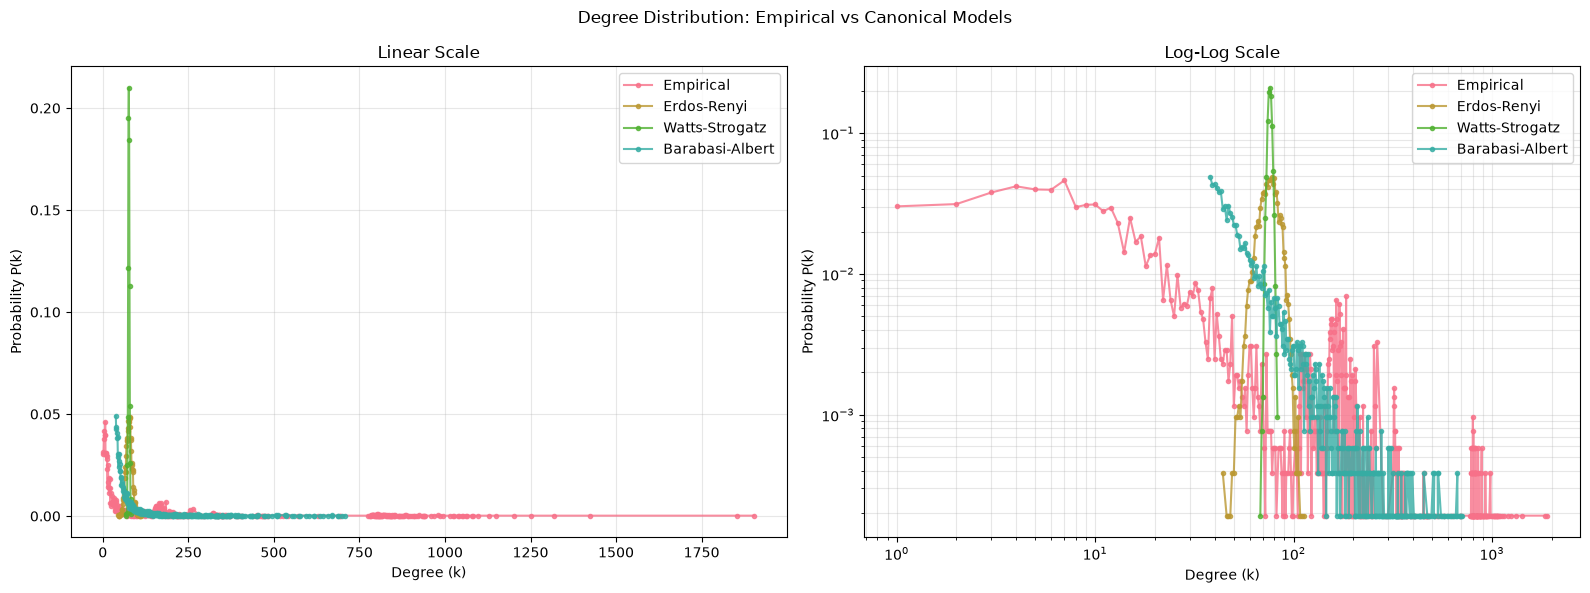

In [43]:
# Compare degree distributions: linear and logarithmic scales

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, graph in networks.items():

    degrees = [d for _, d in graph.degree()]

    degree_counts = Counter(degrees)
    total_nodes = len(degrees)

    degree_values = sorted(degree_counts.keys())
    probabilities = [
        degree_counts[k] / total_nodes for k in degree_values
    ]

    # Linear scale
    axes[0].plot(
        degree_values, probabilities,
        marker='o', markersize=3,
        label=name, alpha=0.8
    )

    # Log-log scale
    axes[1].plot(
        degree_values, probabilities,
        marker='o', markersize=3,
        label=name, alpha=0.8
    )

axes[0].set_xlabel("Degree (k)")
axes[0].set_ylabel("Probability P(k)")
axes[0].set_title("Linear Scale")
axes[0].grid(alpha=0.3)

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel("Degree (k)")
axes[1].set_ylabel("Probability P(k)")
axes[1].set_title("Log-Log Scale")
axes[1].grid(alpha=0.3, which='both')

for ax in axes:
    ax.legend()

plt.suptitle("Degree Distribution: Empirical vs Canonical Models")
plt.tight_layout()
plt.savefig(
    'degree_distribution_canonical_comparison.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### Robustness Analysis

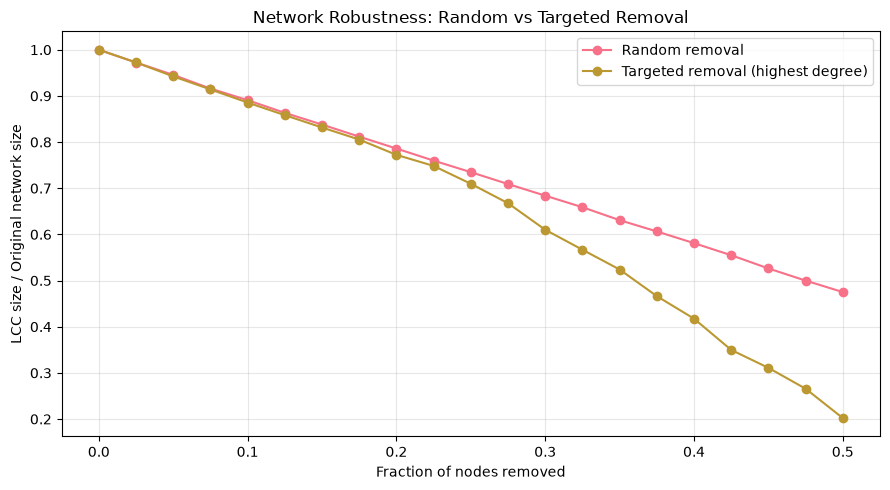

In [44]:
def robustness_analysis(G, removal_steps=20):
    """
    Compare network robustness under random and targeted node removal.

    Targeted removal ranks nodes by their degree in the original network.
    The function plots the largest connected component (LCC) size, expressed
    as a fraction of the original network size, as nodes are removed.

    Args:
        G (networkx.Graph): Network on which the robustness analysis is performed.
        removal_steps (int): Number of removal increments between 0% and 50%
            of the original nodes. Defaults to 20.

    Returns:
        None
    """

    N = G.number_of_nodes()
    fractions = np.linspace(0, 0.5, removal_steps + 1)

    # Random removal
    random_sizes = []

    # Targeted removal (highest degree first)
    targeted_sizes = []

    # Random node order
    rng = np.random.default_rng(42)
    random_order = rng.permutation(list(G.nodes()))

    # Targeted node order
    targeted_order = [
        node for node, degree in
        sorted(G.degree(), key=lambda x: x[1], reverse=True)
    ]

    for fraction in fractions:

        n_remove = int(fraction * N)

        # Random removal
        G_random = G.copy()
        G_random.remove_nodes_from(random_order[:n_remove])

        if G_random.number_of_nodes() > 0:
            largest = max(nx.connected_components(G_random), key=len)
            random_sizes.append(len(largest) / N)
        else:
            random_sizes.append(0)

        # Targeted removal
        G_targeted = G.copy()
        G_targeted.remove_nodes_from(targeted_order[:n_remove])

        if G_targeted.number_of_nodes() > 0:
            largest = max(nx.connected_components(G_targeted), key=len)
            targeted_sizes.append(len(largest) / N)
        else:
            targeted_sizes.append(0)

    plt.figure(figsize=(9, 5))

    plt.plot(fractions, random_sizes, marker='o',
             label='Random removal')

    plt.plot(fractions, targeted_sizes, marker='o',
             label='Targeted removal (highest degree)')

    plt.xlabel("Fraction of nodes removed")
    plt.ylabel("LCC size / Original network size")
    plt.title("Network Robustness: Random vs Targeted Removal")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('robustness_network.png', dpi=300, bbox_inches='tight')
    plt.show()

robustness_analysis(G)